In [1]:
import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D  # noqa

import torch
import torch.nn as nn


T_MIN, T_MAX = 4.0, 300.0
Ic0, Tc = 500.0, 85.0
width_tape = 4.3e-3
brass_thickness_each_side = 4.25e-3
length = 1.0
C_eff = 20.0
U0 = 1e-3

def clamp_T(T):
    return np.clip(T, T_MIN, T_MAX)

# Brass lambda(T)
a,b,c,d,e,f,g,h = 0.021035, -1.01835, 4.54083, -5.03374, 3.20536, -1.12933, -0.174057, -0.0038151
def lambda_brass(T):
    T = clamp_T(T)
    x = np.log10(T)
    log10_lambda = a + b*x + c*x**2 + d*x**3 + e*x**4 + f*x**5 + g*x**6 + h*x**7
    log10_lambda = np.clip(log10_lambda, -2.0, 2.3)
    return 10**log10_lambda

def eta_T(T, s_eta=1.0):
    T_eff = clamp_T(T)
    d_th = 2.0 * brass_thickness_each_side
    return s_eta * (2.0 * width_tape * length / d_th) * lambda_brass(T_eff)

def Ic_T(T):
    T_eff = clamp_T(T)
    out = np.zeros_like(T_eff, dtype=float)
    mask = T_eff < Tc
    out[mask] = Ic0 * (1.0 - (T_eff[mask]/Tc)**1.7)
    return out

def resistance_SC(I, T, n=18.0):
    T_eff = clamp_T(T)
    Ic = Ic_T(T_eff)
    R = np.full_like(T_eff, 1e-6, dtype=float)
    mask = (Ic > 0) & (I > 0)
    R[mask] = U0 * I[mask]**(n-1) * Ic[mask]**(-n)
    return R

def Qin(I, T, n=18.0):
    return I**2 * resistance_SC(I, T, n=n)

def Qout(T, T0, s_eta=1.0):
    return eta_T(T, s_eta) * (T - T0)

def time_to_quench_deltaT(T0, I, s_eta=1.0, dT_crit=12.0, n=18.0,
                          t_max=0.5, dt=0.002):
    """
    Time until T reaches T0 + dT_crit, capped at t_max.
    Super simple explicit Euler integrator.
    """
    T = float(T0)
    Tq = T0 + dT_crit
    t = 0.0
    while t < t_max:
        T = clamp_T(T)
        qin = Qin(np.array([I]), np.array([T]), n=n)[0]
        qout = Qout(np.array([T]), np.array([T0]), s_eta=s_eta)[0]
        dTdt = (qin - qout) / C_eff
        T += dTdt * dt
        t += dt
        if T >= Tq:
            return t
    return t_max

# =====================================
# 1) True time-to-quench surface
# =====================================

I0 = 400.0                     # fixed operating current
T0_vals = np.linspace(20, 80, 15)
s_eta_vals = np.linspace(0.4, 1.4, 15)
T0_grid, s_grid = np.meshgrid(T0_vals, s_eta_vals)

tq_grid = np.zeros_like(T0_grid)
for i in range(T0_grid.shape[0]):
    for j in range(T0_grid.shape[1]):
        tq_grid[i,j] = time_to_quench_deltaT(T0_grid[i,j], I0, s_eta=s_grid[i,j])

Lambda_eff = s_grid * lambda_brass(77.0)   # effective cooling axis

# 3D surface of ground truth
fig = plt.figure(figsize=(6,5))
ax = fig.add_subplot(111, projection='3d')
surf = ax.plot_surface(T0_grid, Lambda_eff, tq_grid, cmap="viridis")
ax.set_xlabel("Base Temperature T0 [K]")
ax.set_ylabel("Λ_eff [W/m/K]")
ax.set_zlabel("t_quench [s]")
ax.set_title("True time-to-quench surface (ΔT=12 K, I=400 A)")
fig.colorbar(surf, shrink=0.6, aspect=10, label="t_quench [s]")
plt.tight_layout()
plt.show()

# =====================================
# 2) Sparse training subset + surrogate
# =====================================

# pick N_train points from grid as if they came from full simulator
N_train = 60
rng = np.random.default_rng(0)
flat_idx = np.arange(T0_grid.size)
train_idx = rng.choice(flat_idx, size=N_train, replace=False)
T0_train = T0_grid.ravel()[train_idx]
Lam_train = Lambda_eff.ravel()[train_idx]
y_train = tq_grid.ravel()[train_idx]

X_train = np.stack([T0_train, Lam_train], axis=1)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

class SurrogateMLP(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(2, 32),
            nn.Tanh(),
            nn.Linear(32, 32),
            nn.Tanh(),
            nn.Linear(32, 1)
        )
    def forward(self, x):
        return self.net(x)

model = SurrogateMLP().to(device)
X_t = torch.tensor(X_train, dtype=torch.float32, device=device)
y_t = torch.tensor(y_train, dtype=torch.float32, device=device).unsqueeze(1)

opt = torch.optim.Adam(model.parameters(), lr=1e-3)
for ep in range(301):
    opt.zero_grad()
    pred = model(X_t)
    loss = ((pred - y_t)**2).mean()
    loss.backward()
    opt.step()
    if ep % 100 == 0:
        print(f"epoch {ep}, loss={loss.item():.4e}")

# predictions on full grid
X_full = np.stack([T0_grid.ravel(), Lambda_eff.ravel()], axis=1)
with torch.no_grad():
    Xf_t = torch.tensor(X_full, dtype=torch.float32, device=device)
    tq_pred_flat = model(Xf_t).cpu().numpy().ravel()
tq_pred_grid = tq_pred_flat.reshape(T0_grid.shape)
err_grid = tq_pred_grid - tq_grid

# =====================================
# 3) True surface + training points
# =====================================
fig2 = plt.figure(figsize=(6,5))
ax2 = fig2.add_subplot(111, projection='3d')
surf2 = ax2.plot_surface(T0_grid, Lambda_eff, tq_grid, cmap="viridis", alpha=0.7)
ax2.scatter(T0_train, Lam_train, y_train, c="red", s=30, label="train pts")
ax2.set_xlabel("T0 [K]")
ax2.set_ylabel("Λ_eff [W/m/K]")
ax2.set_zlabel("t_quench [s]")
ax2.set_title("True surface with training points")
ax2.legend()
fig2.colorbar(surf2, shrink=0.6, aspect=10, label="t_quench [s]")
plt.tight_layout()
plt.show()

# =====================================
# 4) 2D heatmaps: true vs surrogate vs error
# =====================================
fig3, axs = plt.subplots(1, 3, figsize=(15,4))

im0 = axs[0].pcolormesh(T0_grid, Lambda_eff, tq_grid, shading="auto")
axs[0].set_title("True t_quench [s]")
axs[0].set_xlabel("T0 [K]")
axs[0].set_ylabel("Λ_eff")
fig3.colorbar(im0, ax=axs[0])

im1 = axs[1].pcolormesh(T0_grid, Lambda_eff, tq_pred_grid, shading="auto")
axs[1].set_title("Surrogate t_quench [s]")
axs[1].set_xlabel("T0 [K]")
axs[1].set_ylabel("Λ_eff")
fig3.colorbar(im1, ax=axs[1])

im2 = axs[2].pcolormesh(T0_grid, Lambda_eff, err_grid, shading="auto")
axs[2].set_title("Error (pred - true) [s]")
axs[2].set_xlabel("T0 [K]")
axs[2].set_ylabel("Λ_eff")
fig3.colorbar(im2, ax=axs[2])

plt.tight_layout()
plt.show()



KeyboardInterrupt



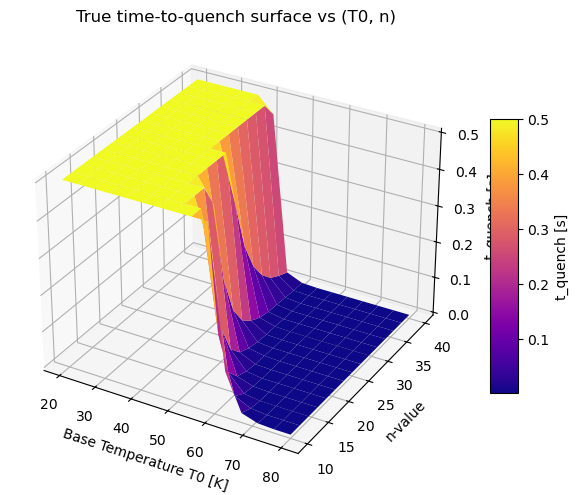

epoch 0, loss=3.1644e-01
epoch 100, loss=3.3312e-02
epoch 200, loss=2.8213e-02
epoch 300, loss=1.7166e-02
epoch 400, loss=8.4957e-03


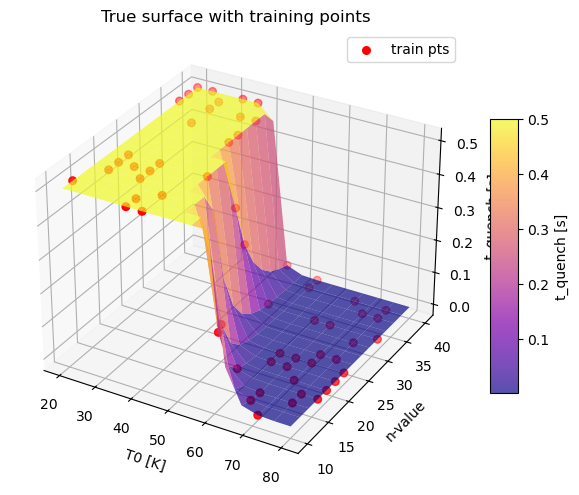

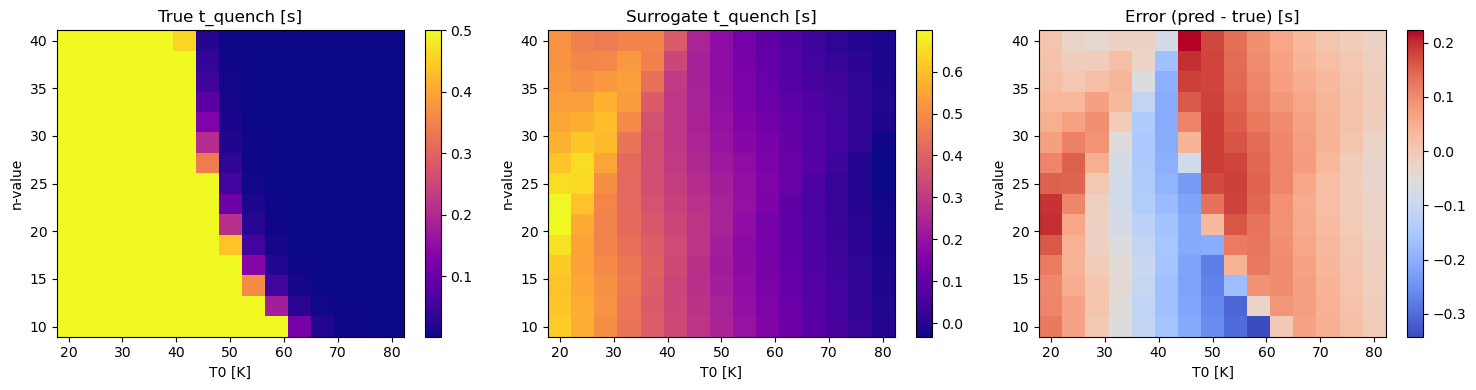

In [42]:
# ============================================
# FIGURE 4(b) ANALOG: t_quench vs T0 & n-value
# ============================================

# Sweep ranges
T0_vals = np.linspace(20, 80, 15)     # base temperature
n_vals  = np.linspace(10, 40, 15)     # n-value (power law exponent)

T0_grid_n, n_grid = np.meshgrid(T0_vals, n_vals)

# fixed operating current
I0 = 400.0

# compute true time-to-quench surface
tq_grid_n = np.zeros_like(T0_grid_n)
for i in range(T0_grid_n.shape[0]):
    for j in range(T0_grid_n.shape[1]):
        tq_grid_n[i,j] = time_to_quench_deltaT(T0_grid_n[i,j], I0,
                                               s_eta=1.0,
                                               dT_crit=12.0,
                                               n=n_grid[i,j])

# -------------------------
# Plot: true surface
# -------------------------
fig = plt.figure(figsize=(6,5))
ax = fig.add_subplot(111, projection='3d')
surf = ax.plot_surface(T0_grid_n, n_grid, tq_grid_n, cmap="plasma")
ax.set_xlabel("Base Temperature T0 [K]")
ax.set_ylabel("n-value")
ax.set_zlabel("t_quench [s]")
ax.set_title("True time-to-quench surface vs (T0, n)")
fig.colorbar(surf, shrink=0.6, aspect=10, label="t_quench [s]")
plt.tight_layout()
plt.show()

# ================================
# Surrogate training (sparse data)
# ================================
N_train = 60
rng = np.random.default_rng(1)
flat_idx = np.arange(T0_grid_n.size)
train_idx = rng.choice(flat_idx, size=N_train, replace=False)

T0_train_n = T0_grid_n.ravel()[train_idx]
n_train_n  = n_grid.ravel()[train_idx]
y_train_n  = tq_grid_n.ravel()[train_idx]

X_train_n = np.stack([T0_train_n, n_train_n], axis=1)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

class SurrogateMLP_N(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(2, 32),
            nn.Tanh(),
            nn.Linear(32, 32),
            nn.Tanh(),
            nn.Linear(32, 1)
        )
    def forward(self, x):
        return self.net(x)

model_n = SurrogateMLP_N().to(device)

X_tn = torch.tensor(X_train_n, dtype=torch.float32, device=device)
y_tn = torch.tensor(y_train_n, dtype=torch.float32, device=device).unsqueeze(1)

opt_n = torch.optim.Adam(model_n.parameters(), lr=1e-3)

# train short
for ep in range(401):
    opt_n.zero_grad()
    pred_n = model_n(X_tn)
    loss = ((pred_n - y_tn)**2).mean()
    loss.backward()
    opt_n.step()
    if ep % 100 == 0:
        print(f"epoch {ep}, loss={loss.item():.4e}")

# ================================
# Evaluate surrogate on full grid
# ================================
X_full_n = np.stack([T0_grid_n.ravel(), n_grid.ravel()], axis=1)
with torch.no_grad():
    Xfn_t = torch.tensor(X_full_n, dtype=torch.float32, device=device)
    tq_pred_flat_n = model_n(Xfn_t).cpu().numpy().ravel()

tq_pred_grid_n = tq_pred_flat_n.reshape(T0_grid_n.shape)
err_grid_n = tq_pred_grid_n - tq_grid_n

# ========================================
# Plot: true surface + training points
# ========================================
fig2 = plt.figure(figsize=(6,5))
ax2 = fig2.add_subplot(111, projection='3d')
surf2 = ax2.plot_surface(T0_grid_n, n_grid, tq_grid_n, cmap="plasma", alpha=0.7)
ax2.scatter(T0_train_n, n_train_n, y_train_n, c="red", s=30, label="train pts")
ax2.set_xlabel("T0 [K]")
ax2.set_ylabel("n-value")
ax2.set_zlabel("t_quench [s]")
ax2.set_title("True surface with training points")
ax2.legend()
fig2.colorbar(surf2, shrink=0.6, aspect=10, label="t_quench [s]")
plt.tight_layout()
plt.show()

# ========================================
# Heatmaps: true vs surrogate vs error
# ========================================
fig3, axs = plt.subplots(1, 3, figsize=(15,4))

im0 = axs[0].pcolormesh(T0_grid_n, n_grid, tq_grid_n, shading="auto", cmap="plasma")
axs[0].set_title("True t_quench [s]")
axs[0].set_xlabel("T0 [K]"); axs[0].set_ylabel("n-value")
fig3.colorbar(im0, ax=axs[0])

im1 = axs[1].pcolormesh(T0_grid_n, n_grid, tq_pred_grid_n, shading="auto", cmap="plasma")
axs[1].set_title("Surrogate t_quench [s]")
axs[1].set_xlabel("T0 [K]"); axs[1].set_ylabel("n-value")
fig3.colorbar(im1, ax=axs[1])

im2 = axs[2].pcolormesh(T0_grid_n, n_grid, err_grid_n, shading="auto", cmap="coolwarm")
axs[2].set_title("Error (pred - true) [s]")
axs[2].set_xlabel("T0 [K]"); axs[2].set_ylabel("n-value")
fig3.colorbar(im2, ax=axs[2])

plt.tight_layout()
plt.show()


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import root_scalar

# ----------------------------
# Constants / baseline settings (paper-style defaults)
# ----------------------------
U0 = 1e-4          # V/m  (criterion electric field)
Ic0 = 500.0        # A
Tc = 85.0          # K (irreversibility temperature used in paper example)
L = 1.0            # m
w = 0.004          # m
d = 0.01           # m (thermal barrier thickness on each side in paper example)
n_fixed = 20.0

EPS_T = 1e-6

# ----------------------------
# Physics: Ic(T) (Eq. 5)
# ----------------------------
def Ic(T):
    # Clip to avoid negative Ic due to numerical overshoot near Tc
    val = Ic0 * (1.0 - (T / Tc)**1.7)
    return np.maximum(val, 1e-12)

# ----------------------------
# Case 1: no stabilizer
# R(I,T) (Eq. 4), Q_in, Q_out, heat balance (Eq. 3)
# ----------------------------
def R_sc_no_stabilizer(I, T, n=n_fixed):
    # R = U0/I * (I/Ic(T))^n
    return (U0 / I) * (I / Ic(T))**n

def Qin_no_stabilizer(I, T, n=n_fixed):
    return I**2 * R_sc_no_stabilizer(I, T, n=n)

def Qout(T, T0, eta):
    return eta * (T - T0)

def heat_balance_case1(T, I, T0, eta, n=n_fixed):
    return Qin_no_stabilizer(I, T, n=n) - Qout(T, T0, eta)

# ----------------------------
# Root existence helper:
# Find equilibrium temperature if it exists (robust bracketing scan)
# ----------------------------
def find_equilibrium_T_case1(I, T0, eta, n=n_fixed, nscan=400):
    Tmin = T0 + 1e-6
    Tmax = Tc - 1e-3
    Ts = np.linspace(Tmin, Tmax, nscan)
    fs = heat_balance_case1(Ts, I, T0, eta, n=n)

    # Find any sign change interval
    for k in range(len(Ts) - 1):
        f1, f2 = fs[k], fs[k+1]
        if np.isnan(f1) or np.isnan(f2):
            continue
        if f1 == 0.0:
            return Ts[k]
        if f1 * f2 < 0:
            sol = root_scalar(
                heat_balance_case1,
                args=(I, T0, eta, n),
                bracket=[Ts[k], Ts[k+1]],
                method="bisect",
                xtol=1e-8,
                rtol=1e-8,
                maxiter=200
            )
            if sol.converged:
                return sol.root
    return None

def exists_equilibrium_case1(I, T0, eta, n=n_fixed):
    return find_equilibrium_T_case1(I, T0, eta, n=n) is not None

# ----------------------------
# Compute runaway (I*, T*) via bisection on I
# ----------------------------
def find_runaway_case1(T0, eta, n=n_fixed, Imax_factor=5.0):
    # Start low stable, and find a high bound with no equilibrium
    Ic_base = Ic(T0)
    I_low = 0.0
    I_high = Imax_factor * Ic_base

    # Ensure I_low is stable (it should be)
    # Ensure I_high is unstable; if not, expand
    while exists_equilibrium_case1(I_high, T0, eta, n=n) and I_high < 50 * Ic_base:
        I_high *= 2.0

    # If even huge I_high still stable, something is off (or extreme cooling)
    if exists_equilibrium_case1(I_high, T0, eta, n=n):
        return np.nan, np.nan, np.nan

    # Bisection
    for _ in range(60):
        I_mid = 0.5 * (I_low + I_high)
        if exists_equilibrium_case1(I_mid, T0, eta, n=n):
            I_low = I_mid
        else:
            I_high = I_mid

    I_star = I_low
    T_star = find_equilibrium_T_case1(I_star, T0, eta, n=n)
    if T_star is None:
        return np.nan, np.nan, np.nan
    return I_star, T_star, (T_star - T0)

# ======================================================================
# Case 2: with stabilizer + current sharing (Eq. 7-8 workflow)
# ======================================================================

# Geometry for stabilized conductor layers (paper example numbers)
t_sc = 1.3e-6      # m
t_cu = 50e-6       # m
t_ss = 50e-6       # m
width = w          # same tape width

A_sc = width * t_sc
A_cu = width * t_cu
A_ss = width * t_ss

# Resistivity models (tunable):
# Paper uses Gruneisen–Bloch for Cu and a polynomial fit for SS. :contentReference[oaicite:6]{index=6}
# Here we provide a simple, stable approximation you can later swap with exact fits.

rho_cu_300 = 1.6e-8
RRR = 24.0
rho_cu_0 = rho_cu_300 / RRR

def rho_cu(T):
    # Simple monotone approximation:
    # residual + phonon term ~ (T/300)^p
    p = 1.5
    rho_ph = (rho_cu_300 - rho_cu_0) * (np.clip(T, 1e-3, 300.0) / 300.0)**p
    return rho_cu_0 + rho_ph

def rho_ss(T):
    # Stainless steel is much higher resistivity, weakly T-dependent at cryo.
    # Use a conservative smooth function (tune later).
    rho_300 = 7.0e-7
    rho_20 = 5.5e-7
    Tclip = np.clip(T, 1e-3, 300.0)
    # linear interpolation in logT space (smooth)
    a = (rho_300 - rho_20) / (np.log(300.0) - np.log(20.0))
    b = rho_20 - a * np.log(20.0)
    return a * np.log(Tclip) + b

def R_layer(rho, A):
    return rho / A  # ohm/m (resistance per unit length)

def Rst(T):
    Rcu = R_layer(rho_cu(T), A_cu)
    Rss = R_layer(rho_ss(T), A_ss)
    # parallel
    return 1.0 / (1.0 / Rcu + 1.0 / Rss)

def Rs_from_Ix(Ix, T, n=n_fixed):
    # superconducting branch resistance per unit length, based on Ix
    # U = U0 (Ix/Ic)^n => Rs = U/Ix
    if Ix <= 0:
        return np.inf
    return (U0 / Ix) * (Ix / Ic(T))**n

def solve_Ix(I, T, n=n_fixed):
    # Solve Eq. (8):
    # U0 * (Ix/Ic(T))^n = (I - Ix) * Rst(T)
    # g(Ix)=0 in [0,I]
    def g(Ix):
        left = U0 * (Ix / Ic(T))**n
        right = (I - Ix) * Rst(T)
        return left - right

    # If I is tiny, Ix ~ I
    if I <= 0:
        return 0.0

    # Bracket [0, I]
    g0 = g(0.0)     # = -I*Rst(T) < 0
    gI = g(I)       # = U0*(I/Ic)^n >= 0
    if np.isnan(g0) or np.isnan(gI):
        return None
    if g0 > 0:
        return 0.0
    if gI < 0:
        return I

    sol = root_scalar(g, bracket=[0.0, I], method="bisect", xtol=1e-10, rtol=1e-10, maxiter=200)
    return sol.root if sol.converged else None

def Reff_stabilized(I, T, n=n_fixed):
    Ix = solve_Ix(I, T, n=n)
    if Ix is None:
        return np.nan
    Rs = Rs_from_Ix(Ix, T, n=n)
    Rst_val = Rst(T)
    # parallel combination Eq. (7 style)
    if np.isinf(Rs):
        return Rst_val
    return (Rs * Rst_val) / (Rs + Rst_val)

def heat_balance_case2(T, I, T0, eta, n=n_fixed):
    Qin = I**2 * Reff_stabilized(I, T, n=n)
    return Qin - Qout(T, T0, eta)

def find_equilibrium_T_case2(I, T0, eta, n=n_fixed, nscan=400):
    Tmin = T0 + 1e-6
    Tmax = Tc - 1e-3
    Ts = np.linspace(Tmin, Tmax, nscan)
    fs = np.array([heat_balance_case2(T, I, T0, eta, n=n) for T in Ts])

    for k in range(len(Ts) - 1):
        f1, f2 = fs[k], fs[k+1]
        if np.isnan(f1) or np.isnan(f2):
            continue
        if f1 == 0.0:
            return Ts[k]
        if f1 * f2 < 0:
            sol = root_scalar(
                lambda T: heat_balance_case2(T, I, T0, eta, n=n),
                bracket=[Ts[k], Ts[k+1]],
                method="bisect",
                xtol=1e-8,
                rtol=1e-8,
                maxiter=250
            )
            if sol.converged:
                return sol.root
    return None

def exists_equilibrium_case2(I, T0, eta, n=n_fixed):
    return find_equilibrium_T_case2(I, T0, eta, n=n) is not None

def find_runaway_case2(T0, eta, n=n_fixed, Imax_factor=8.0):
    Ic_base = Ic(T0)
    I_low = 0.0
    I_high = Imax_factor * Ic_base

    while exists_equilibrium_case2(I_high, T0, eta, n=n) and I_high < 80 * Ic_base:
        I_high *= 2.0

    if exists_equilibrium_case2(I_high, T0, eta, n=n):
        return np.nan, np.nan, np.nan

    for _ in range(60):
        I_mid = 0.5 * (I_low + I_high)
        if exists_equilibrium_case2(I_mid, T0, eta, n=n):
            I_low = I_mid
        else:
            I_high = I_mid

    I_star = I_low
    T_star = find_equilibrium_T_case2(I_star, T0, eta, n=n)
    if T_star is None:
        return np.nan, np.nan, np.nan
    return I_star, T_star, (T_star - T0)

# ======================================================================
# RUN: build surfaces
# ======================================================================

def eta_from_lambda(lmbda):
    return (2.0 * w * L / d) * lmbda

# Grid like paper intent: T0 and lambda; n fixed
T0_grid = np.linspace(5.0, 75.0, 36)               # 5..75 K
lambda_grid = np.logspace(np.log10(0.5), np.log10(500.0), 40)  # W/mK

Istar1 = np.zeros((len(T0_grid), len(lambda_grid)))
DT1    = np.zeros_like(Istar1)
Inorm1 = np.zeros_like(Istar1)

Istar2 = np.zeros_like(Istar1)
DT2    = np.zeros_like(Istar1)
Inorm2 = np.zeros_like(Istar1)

print("Computing Case 1 surfaces (no stabilizer)...")
for i, T0v in enumerate(T0_grid):
    for j, lv in enumerate(lambda_grid):
        eta = eta_from_lambda(lv)
        I_s, T_s, dT = find_runaway_case1(T0v, eta, n=n_fixed)
        Istar1[i, j] = I_s
        DT1[i, j]    = dT
        Inorm1[i, j] = I_s / Ic(T0v) if np.isfinite(I_s) else np.nan

print("Computing Case 2 surfaces (with stabilizer + current sharing)...")
for i, T0v in enumerate(T0_grid):
    for j, lv in enumerate(lambda_grid):
        eta = eta_from_lambda(lv)
        I_s, T_s, dT = find_runaway_case2(T0v, eta, n=n_fixed)
        Istar2[i, j] = I_s
        DT2[i, j]    = dT
        Inorm2[i, j] = I_s / Ic(T0v) if np.isfinite(I_s) else np.nan

# ======================================================================
# PLOT: surfaces as heatmaps (easy to inspect)
# ======================================================================
def plot_heatmap(Z, title, xlabel, ylabel, xvals, yvals, logx=True):
    plt.figure()
    # imshow expects uniform grid; our lambda is logspaced but monotone — OK for qualitative
    plt.imshow(Z, origin='lower', aspect='auto')
    plt.title(title)
    plt.xlabel(xlabel)
    plt.ylabel(ylabel)
    plt.colorbar(label='value')
    # Tick labels
    xt = np.linspace(0, len(xvals)-1, 6).astype(int)
    yt = np.linspace(0, len(yvals)-1, 6).astype(int)
    plt.xticks(xt, [f"{xvals[k]:.2g}" for k in xt], rotation=30)
    plt.yticks(yt, [f"{yvals[k]:.1f}" for k in yt])
    plt.tight_layout()

# Case 1
plot_heatmap(Inorm1, "Case 1: I*/Ic(T0) (no stabilizer)", "lambda index (W/mK)", "T0 index (K)", lambda_grid, T0_grid)
plot_heatmap(DT1,    "Case 1: ΔT* (K) (no stabilizer)",   "lambda index (W/mK)", "T0 index (K)", lambda_grid, T0_grid)

# Case 2
plot_heatmap(Inorm2, "Case 2: I*/Ic(T0) (with stabilizer)", "lambda index (W/mK)", "T0 index (K)", lambda_grid, T0_grid)
plot_heatmap(DT2,    "Case 2: ΔT* (K) (with stabilizer)",   "lambda index (W/mK)", "T0 index (K)", lambda_grid, T0_grid)

plt.show()

# ======================================================================
# VALIDATION PRINTS (paper-style qualitative checks)
# ======================================================================
def monotone_check_increasing_eta(Inorm, T0_grid, lambda_grid):
    # For each T0 row: check mostly nondecreasing with lambda
    bad = 0
    tot = 0
    for i in range(len(T0_grid)):
        row = Inorm[i, :]
        for j in range(len(lambda_grid)-1):
            if np.isfinite(row[j]) and np.isfinite(row[j+1]):
                tot += 1
                if row[j+1] + 1e-6 < row[j]:
                    bad += 1
    return bad, tot

bad1, tot1 = monotone_check_increasing_eta(Inorm1, T0_grid, lambda_grid)
bad2, tot2 = monotone_check_increasing_eta(Inorm2, T0_grid, lambda_grid)

print(f"[Check] Case 1 monotonic vs cooling violations: {bad1}/{tot1}")
print(f"[Check] Case 2 monotonic vs cooling violations: {bad2}/{tot2}")

# ΔT should generally decrease with T0 for fixed lambda:
def trend_check_DT_decreases_with_T0(DT, lambda_index=10):
    col = DT[:, lambda_index]
    # count increases
    inc = np.sum(np.diff(col) > 0)
    return inc, len(col)-1

inc1, ncomp1 = trend_check_DT_decreases_with_T0(DT1, lambda_index=10)
inc2, ncomp2 = trend_check_DT_decreases_with_T0(DT2, lambda_index=10)
print(f"[Check] Case 1 ΔT increases with T0 (should be rare): {inc1}/{ncomp1}")
print(f"[Check] Case 2 ΔT increases with T0 (should be rare): {inc2}/{ncomp2}")


Computing Case 1 surfaces (no stabilizer)...
Computing Case 2 surfaces (with stabilizer + current sharing)...


In [ ]:
### gym iimpelentation 
